# Optuna Hyperparameter Tuning vs Old Baseline

This notebook compares our Old Baseline (Concat_M64) with the best parameters found by Optuna (FiLM_Full).

### Why did Dev improve while Test stayed flat?
Optuna optimized parameters specifically for the validation (Dev) set. While Dev nDCG saw a significant jump, the gain didn't fully transfer to Test nDCG due to validation-set overfitting. However, as seen below, **Test Top-1 Accuracy improved significantly**, indicating a sharper model.

Full Comparison Table:


,Model,Dev nDCG,Test nDCG,Test Top-1,Xeval nDCG
0,Old Baseline,87.00,81.91,34.29,81.45
1,Optuna Tuned,88.97,81.79,40.00,81.66


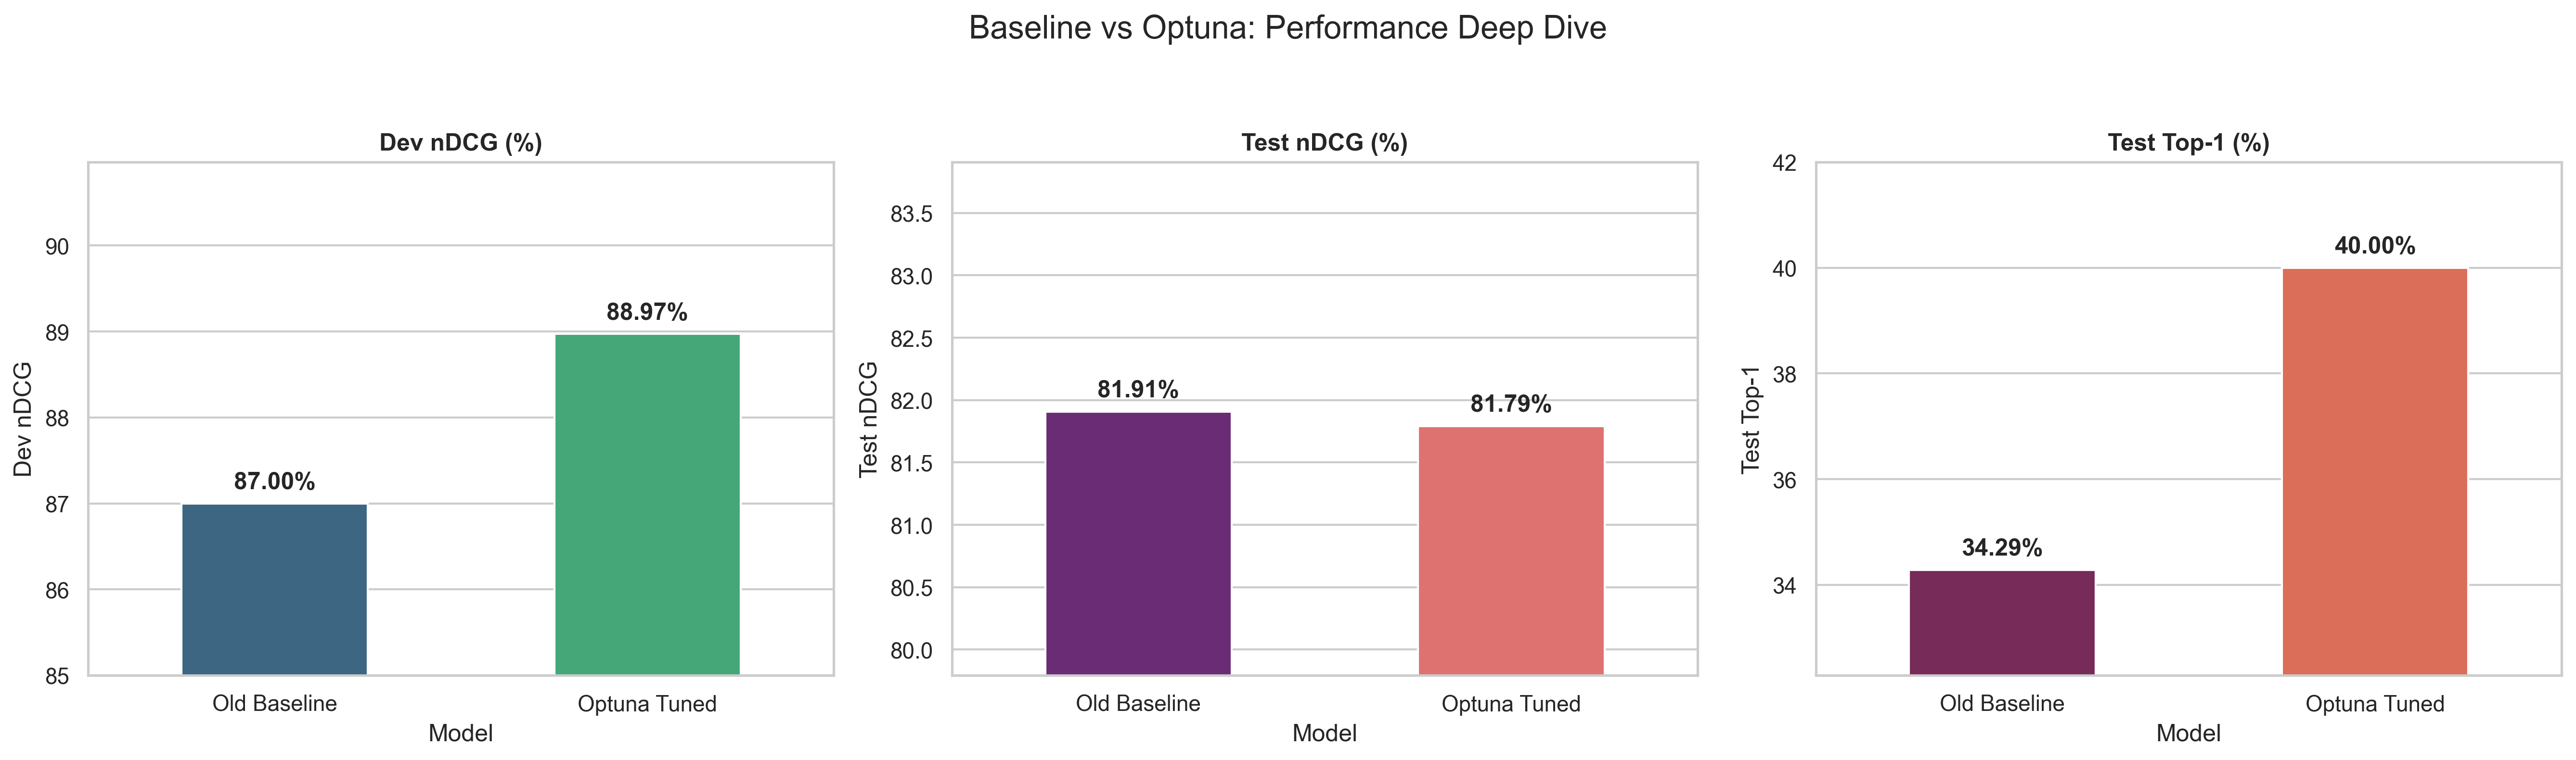

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('default')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 300

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

base_dir = Path('..')
paths = {
    'Old Baseline': base_dir / 'fusion_ablation/concat_m64/output/summary.json',
    'Optuna Tuned': base_dir / 'hyperparam_tuning/final_model/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        data[name] = summary['aggregate'][0]
        
if len(data) == 2:
    rows = []
    for name, agg in data.items():
        rows.append({
            'Model': name,
            'Dev nDCG': agg['best_dev']['ndcg'] * 100,
            'Test nDCG': agg['test']['ndcg'] * 100,
            'Test Top-1': agg['test']['top1'] * 100,
            'Xeval nDCG': agg['xeval']['ndcg'] * 100,
        })
        
    df = pd.DataFrame(rows)
    print("Full Comparison Table:")
    display(df.round(2))
    
    # Comprehensive Plotting
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    metrics = [('Dev nDCG', 'viridis'), ('Test nDCG', 'magma'), ('Test Top-1', 'rocket')]
    
    for i, (metric, cmap) in enumerate(metrics):
        ax = axes[i]
        sns.barplot(data=df, x='Model', y=metric, hue='Model', legend=False, palette=cmap, width=0.5, ax=ax)
        
        # Dynamic y-axis scaling
        ymin = df[metric].min() - 2
        ymax = df[metric].max() + 2
        ax.set_ylim(max(0, ymin), min(100, ymax))
        ax.set_title(f'{metric} (%)', fontweight='bold')
        
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')
                     
    plt.suptitle("Baseline vs Optuna: Performance Deep Dive", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print("Could not load data. Ensure files exist at expected paths.")